# Supervised learning: how a model learns

<div class="roadmap"><div class="rm-sofar"><span>So far</span>Clustering found groups in the counts, and could not name them.</div><div class="rm-question"><b>What does it mean to learn from examples?</b><span>A rule with adjustable numbers is fitted to rows with known answers, and scored on rows it has never seen.</span></div><div class="rm-steps"><div class="rm-step"><b>Two tasks</b><span>a category or a number</span></div><div class="rm-step"><b>A rule with parameters</b><span>a line, a boundary</span></div><div class="rm-step"><b>Training</b><span>the computer sets the parameters</span></div><div class="rm-step"><b>Unseen rows</b><span>the honest score</span></div><div class="rm-step"><b>Flexibility</b><span>how freely the rule may bend</span></div></div></div>

Part 1 of the lecture said what supervised learning is: a model learns a mapping from inputs to outputs from examples with known answers, in order to predict the answers for new, unseen data. This page takes that sentence apart in ten steps.

## 1. Two tasks: a category or a number

First two pictures with made-up points. On the left every point is an object seen from the air, and for each we know whether it is a tree or a building. For a new object we want the answer *tree* or *building*, which is a category: this task is called **classification**. On the right every point is a flat whose rent we know. For a new flat we want a number of euros: this task is called **regression**.

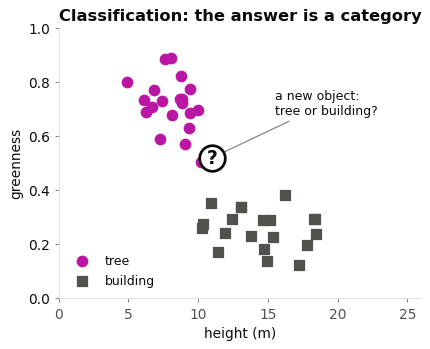

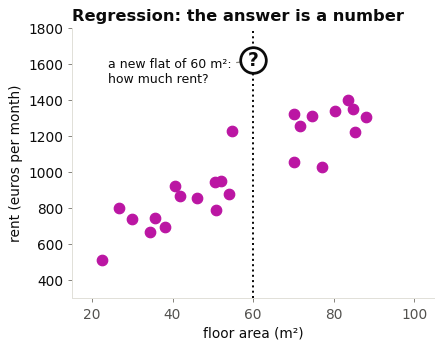

In [15]:
toy = np.random.default_rng(1)          # made-up data, for these two pictures only
trees = np.c_[toy.normal(8, 2.4, 20), toy.normal(0.72, 0.08, 20)]            # height in metres, greenness between 0 and 1
buildings = np.c_[toy.normal(15, 3.8, 20), toy.normal(0.27, 0.09, 20)]
area = toy.uniform(22, 98, 24)                                               # floor area of a flat, in square metres
rent = 300 + 12.5 * area + toy.normal(0, 95, 24)                             # its monthly rent, in euros

fig_c, ax = plt.subplots(figsize=(5.2, 3.9))
ax.scatter(*trees.T, s=70, marker="o", color=h.ACCENT, label="tree")
ax.scatter(*buildings.T, s=70, marker="s", color=h.SECONDARY, label="building")
ax.scatter([11], [0.52], s=420, marker="o", facecolor="white", edgecolor=h.INK, linewidths=2.2, zorder=5)
ax.annotate("?", (11, 0.52), ha="center", va="center", fontsize=15, fontweight="bold", zorder=6)
ax.annotate("a new object:\ntree or building?", (11, 0.52), xytext=(15.5, 0.72), fontsize=10, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=h.MUTED, shrinkB=11))
ax.set_xlabel("height (m)"), ax.set_ylabel("greenness")
ax.set_xlim(0, 26), ax.set_ylim(0, 1)
ax.legend(loc="lower left", fontsize=10)
ax.set_title("Classification: the answer is a category")
h.save(fig_c, "0_toy_classification.png", SAVE, untitled=True)

fig_r, ax = plt.subplots(figsize=(5.2, 3.9))
ax.scatter(area, rent, s=70, color=h.ACCENT)
ax.axvline(60, color=h.INK, lw=1.6, ls=":")
ax.scatter([60], [1620], s=420, marker="o", facecolor="white", edgecolor=h.INK, linewidths=2.2, zorder=5)
ax.annotate("?", (60, 1620), ha="center", va="center", fontsize=15, fontweight="bold", zorder=6)
ax.annotate("a new flat of 60 m²:\nhow much rent?", (60, 1620), xytext=(24, 1560), fontsize=10, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=h.MUTED, shrinkB=11))
ax.set_xlabel("floor area (m²)"), ax.set_ylabel("rent (euros per month)")
ax.set_xlim(15, 105), ax.set_ylim(300, 1800)
ax.set_title("Regression: the answer is a number")
h.save(fig_r, "0_toy_regression.png", SAVE, untitled=True)
plt.show()

Both tasks need rows whose answer is known, and this makes them **supervised learning**. When no answers are known, a method such as k-means (the page on unsupervised learning) can still find groups of similar rows. That is clustering, and it differs from classification in one respect: the groups come without names, so someone has to decide afterwards what each group is. Remote sensing calls this procedure *unsupervised classification*: the pixels are clustered first and the clusters are named afterwards.

## 2. The same two tasks on our hexagons

Our table holds one answer of each kind. The land-use label is a category, and the share of built-up land is a number. The numbers 1 to 5 on the maps are the five hexagons of the table on the page [The data](data): Otaniemi, Tikkurila, Kontula, Seurasaari and Nuuksio.

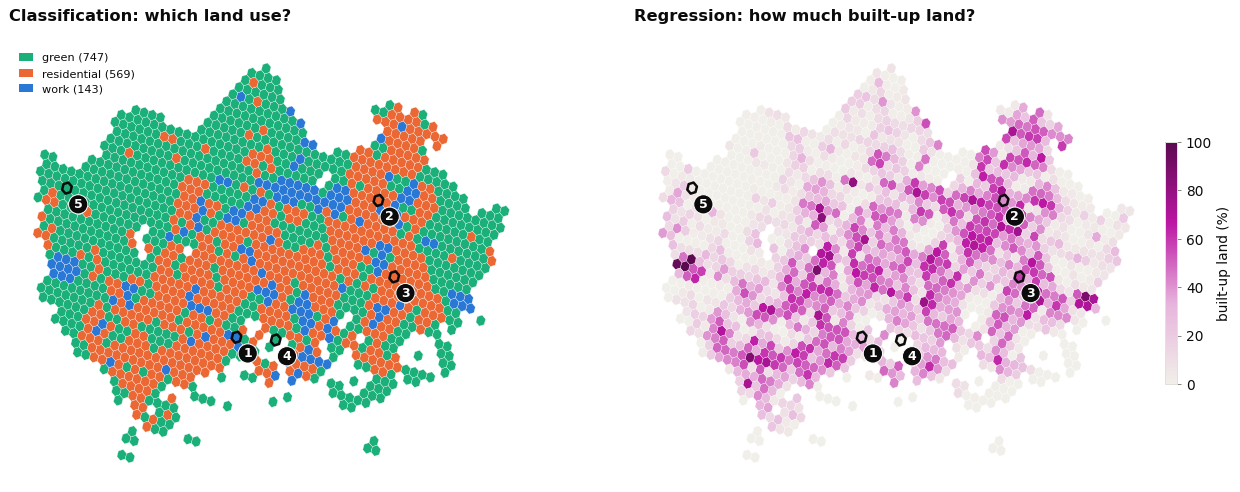

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, y, ax=axes[0], title="Classification: which land use?", places=False)
h.map_values(hexes, built_up_pct, ax=axes[1], title="Regression: how much built-up land?", label="built-up land (%)",
             cmap=h.accent_cmap(), places=False)
for ax in axes:
    h.number_hexagons(ax, hexes, FIVE)
plt.tight_layout()
plt.show()

if SAVE:    # small maps for the corners of the slides: the same five rows on every one of them
    small = {"0_inset_landuse.png": dict(labels=y), "0_inset_builtup.png": dict(values=built_up_pct),
             "0_inset_pois.png": dict(values=np.log10(1 + hexes["poi_total"].to_numpy(float)))}
    for name, what in small.items():
        fig = h.inset_map(hexes, rows=FIVE, **what)
        h.save(fig, name)
        plt.close(fig)
    fig, ax = plt.subplots(figsize=(8.6, 6))
    h.map_classes(hexes, y, ax=ax, places=False)
    h.number_hexagons(ax, hexes, FIVE)
    h.save(fig, "0_five_rows_map_plain.png")
    plt.close(fig)

## 3. A number: more points of interest, more built-up land

We take the regression task first. In the plot below every dot is a hexagon: its number of points of interest runs across, and its share of built-up land runs upwards. The horizontal axis is stretched (it is logarithmic), because a few hexagons in the centre hold hundreds of points of interest and most hold a handful. The purpose of the plot is one question: do hexagons with more points of interest have more built-up land?

median share of built-up land (%), by the number of points of interest in the hexagon
none              0.0
1 to 10           6.0
11 to 50         29.0
51 to 200        42.0
more than 200    39.0


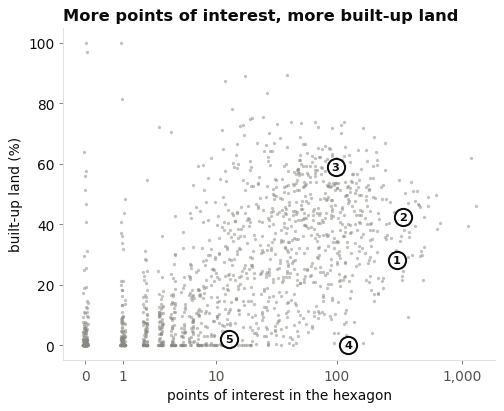

In [17]:
poi_total = hexes["poi_total"].to_numpy(float)
poi_log = np.log10(1 + poi_total).reshape(-1, 1)        # log10(1 + count): the values 0, 1, 2, 3 stand for 0, 9, 99 and 999 points of interest
xs = np.linspace(0, poi_log.max(), 400).reshape(-1, 1)


def poi_scatter(ax):
    """Every hexagon as a dot: points of interest across, built-up land upwards. The five rows of the table are numbered."""
    ax.scatter(h.spread(poi_log.ravel(), 0.02), built_up_pct, s=7, color=h.MUTED, alpha=0.5, linewidths=0)
    for n, i in enumerate(FIVE, 1):
        ax.scatter(poi_log[i, 0], built_up_pct[i], s=190, facecolor="white", edgecolor=h.INK, linewidths=1.6, zorder=6)
        ax.annotate(str(n), (poi_log[i, 0], built_up_pct[i]), ha="center", va="center", fontsize=9, fontweight="bold", zorder=7)
    h.count_ticks(ax, "x", [0, 1, 10, 100, 1000], lambda c: np.log10(1 + c))
    ax.set_ylim(-5, 105)
    ax.set_xlabel("points of interest in the hexagon")
    ax.set_ylabel("built-up land (%)")


bands = pd.cut(pd.Series(poi_total), [-1, 0, 10, 50, 200, 5000], labels=["none", "1 to 10", "11 to 50", "51 to 200", "more than 200"])
by_band = pd.Series(built_up_pct).groupby(bands, observed=True).median().round(0)
print("median share of built-up land (%), by the number of points of interest in the hexagon")
print(by_band.to_string())
h.note("bands", {k: int(v) for k, v in by_band.items()}, SAVE)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
poi_scatter(ax)
ax.set_title("More points of interest, more built-up land")
h.save(fig, "0_relationship.png", SAVE, untitled=True)
plt.show()

The data suggest a relationship: without points of interest the typical hexagon has no built-up land, and with 51 to 200 of them it has about four tenths. Such a statement is still loose. To predict with it we have to state it as a rule that returns one number for any hexagon.

## 4. A model: a line with two parameters

The simplest rule of this kind is a straight line. Call the feature x and the answer y; the line is then *y = a + b × x*. It has two numbers in it. The number **a** is where the line starts, and the number **b** is how steep it is. These numbers are the **parameters** of the model. The picture shows three choices of a and b for a few made-up points. Every choice gives another line, and every line lies at another distance from the points. That distance is the **error** of the line: the short vertical strokes show it point by point, and the typical error is their root mean square.

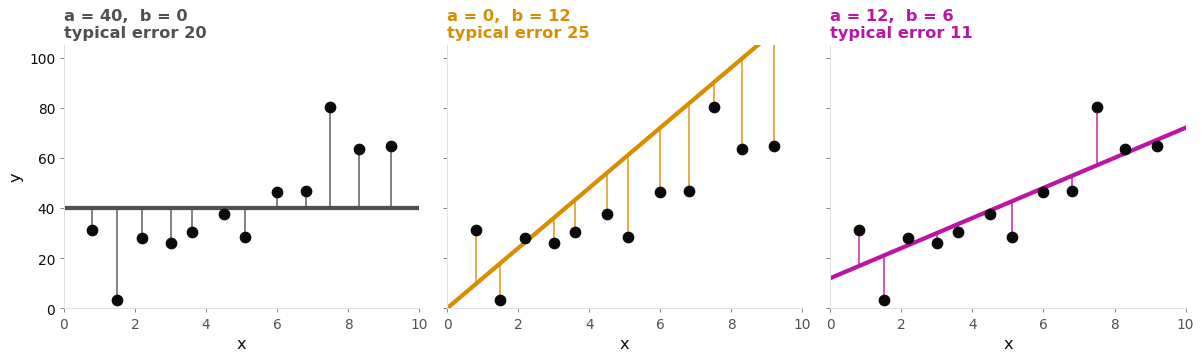

In [18]:
toy_x = np.array([0.8, 1.5, 2.2, 3.0, 3.6, 4.5, 5.1, 6.0, 6.8, 7.5, 8.3, 9.2])          # made-up points, for this picture only
toy_y = 12 + 6 * toy_x + np.random.default_rng(3).normal(0, 7, len(toy_x))


def toy_error(a, b):
    """The typical error of the line y = a + b x on the made-up points: the root of the mean squared distance."""
    return float(np.sqrt(((a + b * toy_x - toy_y) ** 2).mean()))


choices = [(40, 0, h.SECONDARY), (0, 12, "#d98e00"), (12, 6, h.ACCENT)]          # a, b and the colour of the line
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
for ax, (a, b, colour) in zip(axes, choices):
    ax.vlines(toy_x, toy_y, a + b * toy_x, color=colour, lw=1.6, alpha=0.7)          # the error, point by point
    ax.plot([0, 10], [a, a + 10 * b], color=colour, lw=3.4)
    ax.scatter(toy_x, toy_y, s=70, color=h.INK, zorder=3)
    ax.set_title(f"a = {a},  b = {b}\ntypical error {toy_error(a, b):.0f}", color=colour, fontsize=14)
    ax.set_xlim(0, 10), ax.set_ylim(0, 105)
    ax.set_xlabel("x", fontsize=13)
axes[0].set_ylabel("y", fontsize=13)
plt.tight_layout()
h.save(fig, "0_line_parameters.png", SAVE)
plt.show()
h.note("toy_points", {"x": [round(float(v), 2) for v in toy_x], "y": [round(float(v), 1) for v in toy_y]}, SAVE)
h.note("toy_line", [{"a": a, "b": b, "error": round(toy_error(a, b))} for a, b, _ in choices], SAVE)

**Try it.** Move a and b. The short strokes are the errors, and the number is the typical error of your line. Can you get below 11?

<div class="linelab"></div>

On our hexagons, x is the number of points of interest and y is the share of built-up land. Since the counts run from 0 to more than a thousand, x is read on the stretched axis of step 3 (it is log10 of 1 + the count, so that one step of x stands for about ten times as many points of interest). The cell fits the line with the smallest error and shows, for the five rows of the table, what the line says and by how much it is off.

In [19]:
line = LinearRegression().fit(poi_log, built_up_pct)
a_fit, b_fit = float(line.intercept_), float(line.coef_[0])


def typical_error(a, b):
    """How far a line lies from the hexagons: the root of the mean squared error, in points of built-up share."""
    return float(np.sqrt(((a + b * poi_log.ravel() - built_up_pct) ** 2).mean()))


line_rows = pd.DataFrame({"place": list(FIVE_PLACES), "points of interest": poi_total[FIVE].astype(int),
                          "built-up land (%)": built_up_pct[FIVE].round(0).astype(int),
                          "the line says (%)": line.predict(poi_log[FIVE]).round(0).astype(int)}, index=range(1, 6))
line_rows["error"] = line_rows["the line says (%)"] - line_rows["built-up land (%)"]
new_row = int(round(a_fit + b_fit * np.log10(1 + 50)))
print(f"y = {a_fit:.1f} + {b_fit:.1f} x, with x = log10(1 + number of POIs) and y = built-up land (%)       R2 = {line.score(poi_log, built_up_pct):.2f}")
print(f"typical error: {typical_error(0, 0):.0f} points with a = 0, b = 0;  {typical_error(built_up_pct.mean(), 0):.0f} with a flat line at the average;  "
      f"{typical_error(a_fit, b_fit):.0f} with the fitted line")
print(f"a new hexagon with 50 points of interest: the line answers {new_row}% built-up land")
h.note("line", {"a": round(a_fit, 1), "b": round(b_fit, 1), "r2": round(float(line.score(poi_log, built_up_pct)), 2),
                "error_zero": round(typical_error(0, 0)), "error_flat": round(typical_error(built_up_pct.mean(), 0)),
                "error_fit": round(typical_error(a_fit, b_fit)), "mean": round(float(built_up_pct.mean())), "new_row_50": new_row,
                "rows": line_rows.reset_index(drop=True).to_dict("records")}, SAVE)
line_rows

y = 2.7 + 17.8 x, with x = log10(1 + number of POIs) and y = built-up land (%)       R2 = 0.38
typical error: 32 points with a = 0, b = 0;  21 with a flat line at the average;  17 with the fitted line
a new hexagon with 50 points of interest: the line answers 33% built-up land


,place,points of interest,built-up land (%),the line says (%),error
1,Otaniemi,305,28,47,19
2,Tikkurila,338,42,48,6
3,Kontula,98,59,38,-21
4,Seurasaari,124,0,40,40
5,Nuuksio,13,2,23,21


For Tikkurila the fitted line is 6 points too high, for Kontula 21 points too low, and for Seurasaari, an island with an open-air museum and no built-up land, 40 points too high. Over all hexagons the typical error of this line is 17 points, and **R²** is 0.38: the line accounts for 38% of the differences between hexagons (0 for a flat line at the average, 1 for a rule that hits every dot).

## 5. Training: the computer finds the parameters

We chose the form of the rule, a line. We do not choose a and b: the computer finds them from the rows whose answer is known. It starts somewhere, measures the error of the line, changes both numbers a little in the direction that reduces the error, and repeats. This is called **training** or **fitting**. The cell below does exactly that (the method is called gradient descent) and prints a few of the steps.

In [20]:
def fitting_path(x, t, shown=(0, 1, 2, 4, 8, 16, 32, 300), rate=0.2):
    """Fit t = a + b * x step by step, and return a and b after the steps listed in `shown`."""
    z = (x - x.mean()) / x.std()                     # the same x on a scale that makes the steps even
    a, b, path = 0.0, 0.0, {}
    for step in range(max(shown) + 1):
        if step in shown:
            path[step] = (a - b * x.mean() / x.std(), b / x.std())        # back on the original scale
        off = a + b * z - t
        a, b = a - rate * off.mean(), b - rate * (off * z).mean()
    return path


path = fitting_path(poi_log.ravel(), built_up_pct)
for step, (a, b) in path.items():
    print(f"step {step:3d}: a = {a:5.1f}, b = {b:4.1f}, typical error {typical_error(a, b):4.1f} points")
h.note("training", {"error_start": round(typical_error(*path[0]), 1), "error_end": round(typical_error(*path[300]), 1), "steps": 300}, SAVE)

step   0: a =   0.0, b =  0.0, typical error 31.9 points
step   1: a =   0.5, b =  3.6, typical error 27.4 points
step   2: a =   1.0, b =  6.4, typical error 24.2 points
step   4: a =   1.6, b = 10.5, typical error 20.2 points
step   8: a =   2.3, b = 14.8, typical error 17.5 points
step  16: a =   2.6, b = 17.3, typical error 17.0 points
step  32: a =   2.7, b = 17.8, typical error 16.9 points
step 300: a =   2.7, b = 17.8, typical error 16.9 points


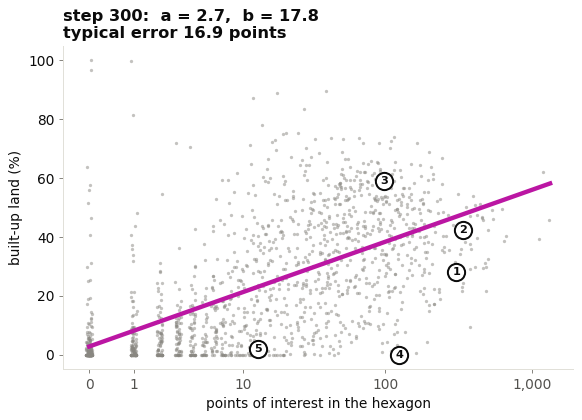

In [21]:
def draw_fit(step):
    a, b = path[step]
    fig, ax = plt.subplots(figsize=(6.6, 4.8))
    poi_scatter(ax)
    ax.plot(xs, a + b * xs.ravel(), color=h.ACCENT, lw=3.5)
    ax.set_title(f"step {step}:  a = {a:.1f},  b = {b:.1f}\ntypical error {typical_error(a, b):.1f} points", fontsize=12)
    fig.tight_layout()
    return fig


fig = draw_fit(300)
h.save(fig, "0_fit_line_end.png", SAVE)
plt.show()
if SAVE:    # the animation for the slides
    h.frames_gif(draw_fit, list(path), "0_fit_line.gif")
    h.frames(draw_fit, list(path), "training")

<div class="frames" data-name="training" data-labels="step 0|step 1|step 2|step 4|step 8|step 16|step 32|step 300"></div>

*Training, step by step: the line on our hexagons after 0, 1, 2, 4, 8, 16, 32 and 300 small changes of a and b.*

After 300 small steps the two numbers no longer change, and they are the a and b that step 4 printed. The fitted line is the **model**. Given a new hexagon, it returns an answer: for 50 points of interest, about a third of the hexagon is built-up land.

## 6. A category: every hexagon is a dot in feature space

Now the classification task. Take two of the 16 counts as two axes and draw every hexagon as a dot. In this plane two hexagons are close when their counts are similar, wherever they lie in the region. Which two counts show the three land uses most clearly apart? The cell tries all 120 pairs. For each pair it fits a rule that separates the land uses (step 7 shows this rule) and notes the share of hexagons the rule gets right.

120 pairs of counts. Share of hexagons that a rule on the pair gets right: best 75%, median 70%, worst 56%.
      count 1         count 2  right
0  shop_daily       education  0.751
1         car            play  0.751
2   education             car  0.751
3         car         lodging  0.748
4         car  craft_industry  0.748

parking and fuel + playgrounds: rank 2 of 120


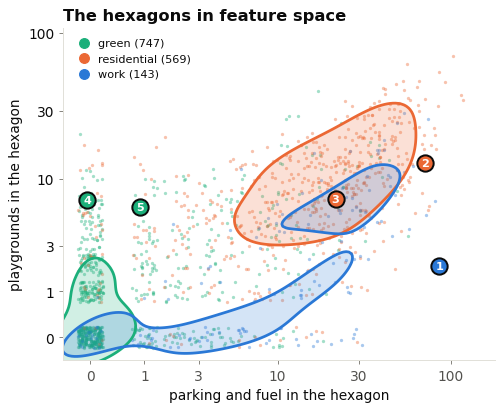

In [22]:
pairs = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        rule = LogisticRegression(max_iter=2000).fit(X[:, [i, j]], y)
        pairs.append({"count 1": FEATURES[i], "count 2": FEATURES[j], "right": rule.score(X[:, [i, j]], y)})
pairs = pd.DataFrame(pairs).sort_values("right", ascending=False).reset_index(drop=True)
print(f"{len(pairs)} pairs of counts. Share of hexagons that a rule on the pair gets right: "
      f"best {pairs['right'].max():.0%}, median {pairs['right'].median():.0%}, worst {pairs['right'].min():.0%}.")
print(pairs.head(5).round(3).to_string())

two = [FEATURES.index("car"), FEATURES.index("play")]          # parking and fuel, playgrounds
names2 = ["parking and fuel in the hexagon", "playgrounds in the hexagon"]
rank = int(pairs.index[(pairs["count 1"] == "car") & (pairs["count 2"] == "play")][0]) + 1
print(f"\nparking and fuel + playgrounds: rank {rank} of {len(pairs)}")
h.note("pairs", {"n": len(pairs), "best": round(float(pairs['right'].max()), 3), "median": round(float(pairs['right'].median()), 3),
                 "rank_car_play": rank, "best_pair": [pairs.loc[0, "count 1"], pairs.loc[0, "count 2"]]}, SAVE)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
h.feature_plane(X[:, two], y, names2, rows=FIVE, ax=ax, title="The hexagons in feature space")
h.save(fig, "0_feature_plane.png", SAVE, untitled=True)
plt.show()

Each shaded region holds the densest half of the hexagons of one land use. Green hexagons sit near zero on both axes. Residential hexagons have both parking and playgrounds, and work hexagons have parking with few playgrounds. The regions overlap, and no pair of counts changes that: the best of the 120 pairs gets three hexagons in four right. The dots are shifted by a small random amount, for drawing only, because counts are whole numbers and hundreds of hexagons would otherwise hide behind each other.

A third count adds a third axis. With offices as the third, the work hexagons rise above the others.

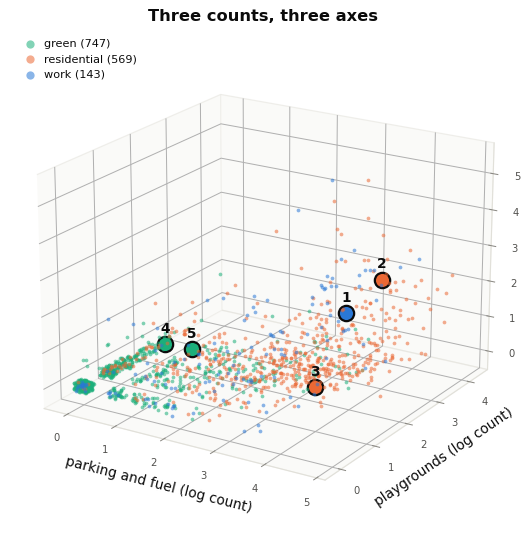

In [23]:
names3 = ["parking and fuel (log count)", "playgrounds (log count)", "offices (log count)"]
three = [FEATURES.index(f) for f in SHOW]

ax = h.feature_space(X[:, three], y, names3, rows=FIVE, title="Three counts, three axes")
h.save(ax.figure, "0_feature_space.png", SAVE)
plt.show()
if SAVE:    # a turning version, kept for those who want it on a slide
    h.spin_gif(lambda azim: h.feature_space(X[:, three], y, names3, rows=FIVE, azim=azim).figure, "0_feature_space.gif")

## 7. For a category, the rule is a boundary

Where the land uses sit in different parts of the plane, a rule can separate them. The same kind of rule as the line of step 4 now draws straight **boundaries**, and its parameters say where they run (the method is called logistic regression). The background colour is the rule's answer for every combination of the two counts.

hexagons on the right side of the boundaries: 75%     always answering 'green': 51%
the same rule with all 16 counts: 79%
parameters that place the boundaries: 9
share of each land use that the rule on two counts finds: green 85%, residential 76%, work 19%


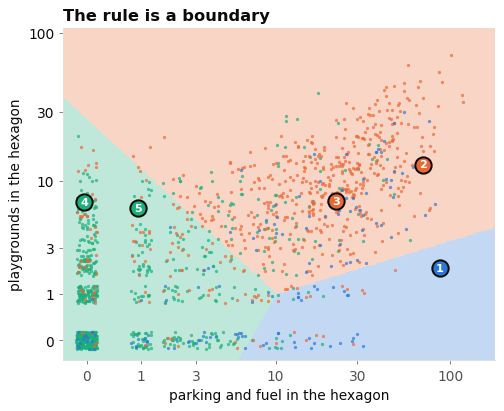

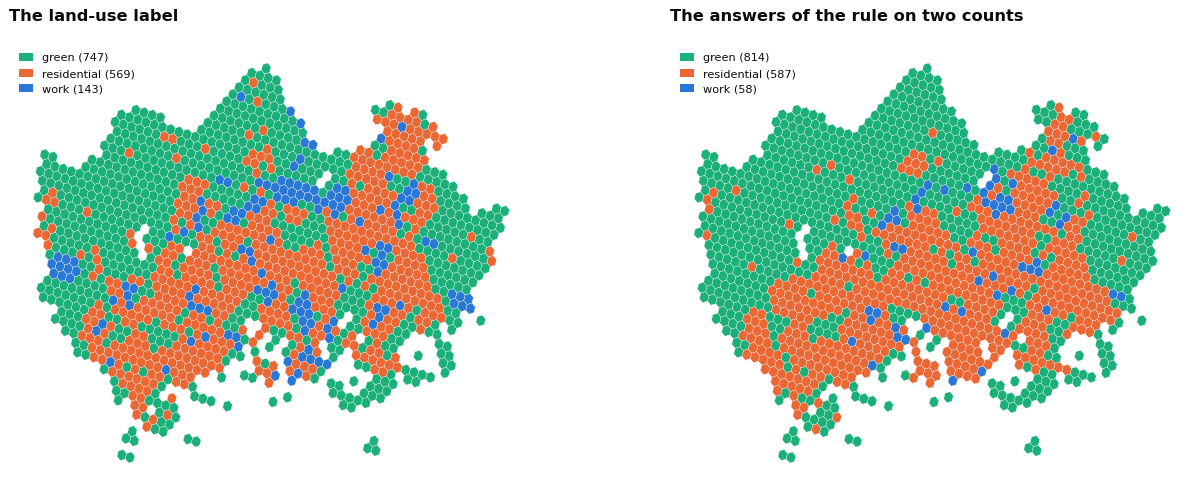

In [24]:
boundary = LogisticRegression(max_iter=2000).fit(X[:, two], y)
all_counts = LogisticRegression(max_iter=3000).fit(X, y)
answers = boundary.predict(X[:, two])
found = {c: float((answers[y == c] == c).mean()) for c in CLASSES}
print(f"hexagons on the right side of the boundaries: {boundary.score(X[:, two], y):.0%}     always answering 'green': {(y == 'green').mean():.0%}")
print(f"the same rule with all 16 counts: {all_counts.score(X, y):.0%}")
print(f"parameters that place the boundaries: {boundary.coef_.size + boundary.intercept_.size}")
print("share of each land use that the rule on two counts finds: " + ", ".join(f"{c} {v:.0%}" for c, v in found.items()))
h.note("boundary", {"two": round(float(boundary.score(X[:, two], y)), 3), "sixteen": round(float(all_counts.score(X, y)), 3),
                    "green": round(float((y == 'green').mean()), 3), "parameters": int(boundary.coef_.size + boundary.intercept_.size),
                    "found": {c: round(v, 2) for c, v in found.items()}}, SAVE)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
h.regions(boundary, X[:, two], y, names2, ax=ax, title="The rule is a boundary", rows=FIVE, counts=(0, 1, 3, 10, 30, 100))
h.save(fig, "0_rule_boundary.png", SAVE, untitled=True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, y, ax=axes[0], title="The land-use label", places=False)
h.map_classes(hexes, answers, ax=axes[1], title="The answers of the rule on two counts", places=False)
plt.tight_layout()
plt.show()
if SAVE:
    fig = h.inset_map(hexes, labels=answers, rows=FIVE)
    h.save(fig, "0_inset_rule.png")
    plt.close(fig)

On the map the rule recovers the large green areas and the residential core, and it fails to find most work areas: two counts are not enough to tell them from residential ones. With all 16 counts the same kind of rule draws its boundaries in a space of 16 axes, which nobody can draw and which works in the same way.

## 8. Why a model is scored on rows it has not seen

Both rules above were fitted and scored on the same rows. That flatters them. To see by how much, we set a fifth of the rows aside before fitting, and compare two models on the rows they learned from and on the rows that were set aside. The first is the boundary rule with all 16 counts. The second is a model that memorises: a decision tree that keeps splitting until it answers every one of its own rows correctly.

In [25]:
def three_piles(seed):
    """Deal the hexagons at random into training (60%), validation (20%) and test (20%)."""
    rest, test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    train, valid = train_test_split(rest, test_size=0.25, stratify=y[rest], random_state=seed)
    return train, valid, test


scores = []
for seed in range(20):
    tr, va, te = three_piles(seed)
    memoriser = DecisionTreeClassifier(random_state=0).fit(X[tr], y[tr])
    rule = LogisticRegression(max_iter=3000).fit(X[tr], y[tr])
    scores.append({"memoriser, seen": memoriser.score(X[tr], y[tr]), "memoriser, unseen": memoriser.score(X[te], y[te]),
                   "rule, seen": rule.score(X[tr], y[tr]), "rule, unseen": rule.score(X[te], y[te])})
scores = pd.DataFrame(scores).mean()
print("share of hexagons answered correctly (means of 20 deals)")
print(scores.map("{:.0%}".format).to_string())
h.note("unseen", {k: round(float(v), 3) for k, v in scores.items()}, SAVE)

share of hexagons answered correctly (means of 20 deals)
memoriser, seen      97%
memoriser, unseen    72%
rule, seen           80%
rule, unseen         79%


> **What did we just see?** On its own rows the memoriser looks far better than the rule. On rows it has not seen it is worse. A score on the rows a model learned from mostly shows how well the model remembers, so it cannot be used to choose between models. (The memoriser does not reach 100% even on its own rows, because some hexagons have identical counts and different labels.)

## 9. Three piles of data

Hence the rows are dealt into piles at random before any learning, and for a reason explained in the next step there are three of them.

- **Training** (60%): the parameters are fitted on these rows.
- **Validation** (20%): we use these rows to choose between versions of the model.
- **Test** (20%): we look at these rows once, at the end. They are the unseen rows.

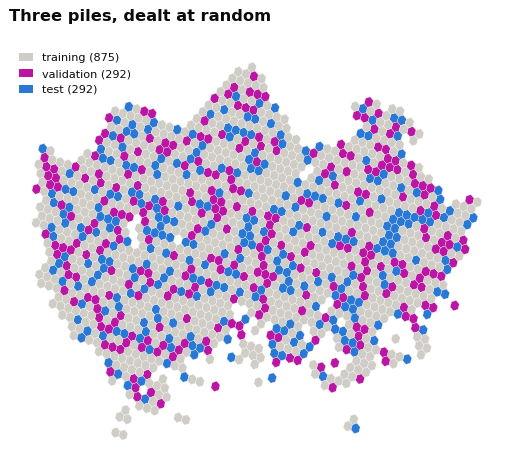

99% of the test hexagons touch at least one training hexagon.


In [26]:
p_train, p_valid, p_test = three_piles(SEED)
piles = np.full(len(y), "training", dtype=object)
piles[p_valid], piles[p_test] = "validation", "test"

fig, ax = plt.subplots(figsize=(8.6, 6))
h.map_piles(hexes, piles, ax=ax, title="Three piles, dealt at random")
h.save(fig, "0_three_piles.png", SAVE)
plt.show()

touching = np.mean([np.isin(W[i].indices, p_train).any() for i in p_test])
print(f"{touching:.0%} of the test hexagons touch at least one training hexagon.")
h.note("piles", {"training": len(p_train), "validation": len(p_valid), "test": len(p_test), "touching": round(float(touching), 2)}, SAVE)

On the map the three piles are thoroughly mixed, and almost every test hexagon touches a training hexagon. It does no harm here, and the page on challenges comes back to it.

## 10. One setting: how flexible may the rule be?

The parameters of a model are found by training. A model also has **settings** that we choose ourselves, before training (the technical word is hyperparameter). For a rule that predicts, the most important setting is how flexible it may be.

We take the regression task of step 3 and three rules: a flat line, a straight line, and a curve that may bend several times (a polynomial of degree 6). To make the point visible we give them little to learn from: 30 hexagons of the training pile.

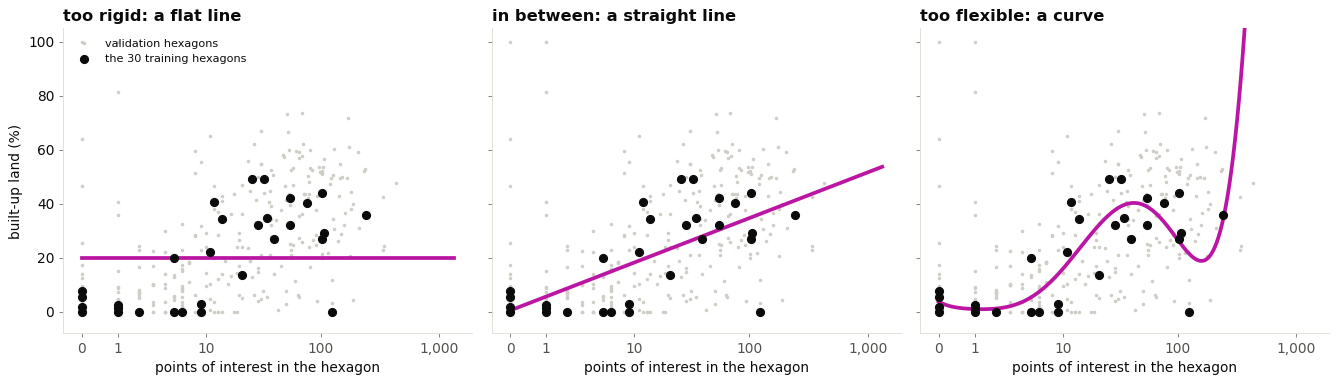

In [27]:
def curve(degree):
    """A polynomial of the given degree: 0 is a flat line, 1 a straight line, 6 a curve that may bend five times."""
    return make_pipeline(MinMaxScaler(), PolynomialFeatures(degree), LinearRegression())


def flex_axes(ax):
    h.count_ticks(ax, "x", [0, 1, 10, 100, 1000], lambda c: np.log10(1 + c))
    ax.set_ylim(-8, 105)
    ax.set_xlabel("points of interest in the hexagon")


few = np.random.default_rng(SEED).choice(p_train, 30, replace=False)       # 30 hexagons of the training pile
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, (degree, word) in zip(axes, {0: "too rigid: a flat line", 1: "in between: a straight line", 6: "too flexible: a curve"}.items()):
    m = curve(degree).fit(poi_log[few], built_up_pct[few])
    ax.scatter(poi_log[p_valid], built_up_pct[p_valid], s=8, color=h.PILES["training"], linewidths=0, label="validation hexagons")
    ax.scatter(poi_log[few], built_up_pct[few], s=40, color=h.INK, zorder=3, label="the 30 training hexagons")
    ax.plot(xs, np.clip(m.predict(xs), -40, 140), color=h.ACCENT, lw=3)
    flex_axes(ax)
    ax.set_title(word)
axes[0].set_ylabel("built-up land (%)")
axes[0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
h.save(fig, "0_flexibility.png", SAVE)
plt.show()

In [28]:
DEGREES = [0, 1, 2, 3, 6, 9]
runs = []
for seed in range(200):                     # 200 deals of the piles, each with its own 30 training hexagons
    tr, va, te = three_piles(seed)
    few_tr = np.random.default_rng(seed).choice(tr, 30, replace=False)
    for degree in DEGREES:
        m = curve(degree).fit(poi_log[few_tr], built_up_pct[few_tr])
        runs.append({"seed": seed, "degree": degree, "training": m.score(poi_log[few_tr], built_up_pct[few_tr]),
                     "validation": m.score(poi_log[va], built_up_pct[va]), "test": m.score(poi_log[te], built_up_pct[te])})
runs = pd.DataFrame(runs)
print("R2, median of 200 deals (30 training hexagons each)")
print(runs.groupby("degree")[["training", "validation"]].median().round(2).to_string())

chosen = runs.loc[runs.groupby("seed")["validation"].idxmax()]
gentle = int((chosen["degree"] <= 3).sum())
print(f"\nThe degree that does best on validation is 1, 2 or 3 in {gentle} of 200 deals.")
print(f"The chosen rule: R2 {chosen['validation'].median():.2f} on the validation pile, {chosen['test'].median():.2f} on the test pile (medians).")
medians = runs.groupby("degree")[["training", "validation"]].median()


def draw_flex(degree):
    """One frame of the animation: the rule of this degree on the 30 hexagons, and its median scores over the 200 deals."""
    words = {0: "too rigid", 1: "in between", 2: "in between", 3: "in between", 6: "too flexible", 9: "much too flexible"}
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.6, 4.6), gridspec_kw={"width_ratios": [2.4, 1]})
    m = curve(degree).fit(poi_log[few], built_up_pct[few])
    ax.scatter(poi_log[p_valid], built_up_pct[p_valid], s=8, color=h.PILES["training"], linewidths=0)
    ax.scatter(poi_log[few], built_up_pct[few], s=40, color=h.INK, zorder=3)
    ax.plot(xs, np.clip(m.predict(xs), -40, 140), color=h.ACCENT, lw=3.5)
    flex_axes(ax)
    ax.set_ylabel("built-up land (%)")
    ax.set_title(f"{words[degree]}  (may bend {max(degree - 1, 0)} times)" if degree > 1 else f"{words[degree]}  ({'a flat line' if degree == 0 else 'a straight line'})")
    tr, va = medians.loc[degree, "training"], medians.loc[degree, "validation"]
    bx.bar([0, 1], [max(tr, 0), max(va, 0)], color=[h.MUTED, h.ACCENT], width=0.6)
    bx.text(0, max(tr, 0) + 0.02, f"{tr:.2f}", ha="center", fontsize=12, fontweight="bold")
    bx.text(1, max(va, 0) + 0.02, f"{va:.2f}" if va > -0.1 else "below 0", ha="center", fontsize=12, fontweight="bold")
    bx.set_xticks([0, 1], ["its own\n30 hexagons", "validation\npile"])
    bx.set_ylim(0, 0.75)
    bx.set_title("R²")
    bx.tick_params(axis="x", length=0)
    fig.tight_layout()
    return fig


if SAVE:    # the animation for the slides
    h.frames_gif(draw_flex, DEGREES, "0_flexibility.gif", ms=1400)
    h.frames(draw_flex, DEGREES, "flexibility")

big = curve(6).fit(poi_log[p_train], built_up_pct[p_train])
big_line = curve(1).fit(poi_log[p_train], built_up_pct[p_train])
print(f"With all {len(p_train)} training hexagons the same curve of degree 6 reaches {big.score(poi_log[p_valid], built_up_pct[p_valid]):.2f} on validation, "
      f"the straight line {big_line.score(poi_log[p_valid], built_up_pct[p_valid]):.2f}.")
h.note("flexibility", {"training": {int(d): round(float(v), 2) for d, v in medians["training"].items()},
                       "validation": {int(d): round(float(v), 2) for d, v in medians["validation"].items()},
                       "gentle_of_200": gentle, "chosen_validation": round(float(chosen["validation"].median()), 2),
                       "chosen_test": round(float(chosen["test"].median()), 2),
                       "all_rows_curve": round(float(big.score(poi_log[p_valid], built_up_pct[p_valid])), 2),
                       "all_rows_line": round(float(big_line.score(poi_log[p_valid], built_up_pct[p_valid])), 2)}, SAVE)

R2, median of 200 deals (30 training hexagons each)
        training  validation
degree                      
0           0.00       -0.02
1           0.40        0.35
2           0.43        0.33
3           0.47        0.33
6           0.53       -0.04
9           0.59     -103.37

The degree that does best on validation is 1, 2 or 3 in 194 of 200 deals.
The chosen rule: R2 0.36 on the validation pile, 0.34 on the test pile (medians).


With all 875 training hexagons the same curve of degree 6 reaches 0.31 on validation, the straight line 0.29.


<div class="frames" data-name="flexibility" data-labels="a flat line|a straight line|may bend once|may bend twice|may bend 5 times|may bend 8 times"></div>

*From a rigid rule to a flexible one, each fitted to the same 30 hexagons (black). The bars are R² on its own 30 hexagons and on the validation pile.*

> **What did we just see?** The flat line is too rigid: it explains nothing, on the rows it has seen and on new ones alike. This is called underfitting. The curve is too flexible: it follows its 30 hexagons more closely than the straight line does, and on new hexagons it is about as bad as the flat line. This is called overfitting, and it is the memoriser of step 8 again. The training rows cannot tell us which rule is best, since they always prefer the most flexible one; the validation pile can. And because we pick the rule that looks best on validation, a third pile, the test pile, is kept for an honest last look. Flexibility hurts when the rows are few: with the whole training pile the same curve does no harm.